# The value of credit bureau data: logistic regression scorecard vs gradient boosting

Data: Kaggle [Home Credit - Credit Risk Model Stability](https://www.kaggle.com/competitions/home-credit-credit-risk-model-stability), with the training CSVs in `data/train`.

Four models are compared: a logistic regression scorecard and CatBoost, each on the lender's own (depth 0) attributes only
and on depth 0 plus aggregated credit bureau (depth 1) attributes. The scorecard follows section 2.2 of
[arXiv:2303.01227](https://arxiv.org/abs/2303.01227): group attribute values, calculate weights of evidence (WOE), select
attributes by information value (IV) and correlation, fit a logistic regression on the WOEs. CatBoost gets the raw values of the
attributes selected for the scorecard.

All four are developed on the weeks up to `TRAIN_END` and tested on the weeks after it. The notebook produces

1. the number of cases and the default rate by week,
2. AUC by period and by week, with and without the bureau data,
3. actual default rates against mean predicted PDs, before and after recalibration,
4. the loss avoided and the net benefit when each model rejects the same share of cases, the ones it gives the highest PD,
5. bootstrap confidence intervals for the differences between the models.

The later weeks cover the covid lockdown and a loan moratorium, so the default rates there are not representative of normal conditions.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import polars as pl
from catboost import CatBoostClassifier
from scipy.optimize import brentq
from scipy.special import expit, logit
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

## Settings

In [2]:
DIR = 'data/train/'
PATH = 'data/features.parquet'  # one row per case, written by the feature pipeline
DEPTH0 = ['train_base.csv', 'train_static_0_0.csv', 'train_static_cb_0.csv']
TRAIN_END, TEST_END = 80, 91  # last training week and last test week
COVID = 68       # first week counted as after covid
MIN_IV = 0.02    # Siddiqi: 0.02 weak, 0.1 medium, 0.3 strong
MAX_CORR = 0.95  # of a group of attributes correlated above this, only the one with the highest IV is kept
EVERY = 1        # use every n-th case
TOP = 20         # attributes listed by IV for each set
EAD = 'credamount_770A'  # loan amount or credit card limit, taken as the exposure at default
LGD = 0.5        # assumed loss given default, as a share of the exposure
MARGIN = 0.08    # assumed profit on a loan that does not default, as a share of the loan amount
REJECT = 0.03    # share of the test cases each model rejects: the ones it gives the highest PD
BOOT = 1000      # bootstrap resamples of the test cases
RECAL = 13       # the PDs are recalibrated to the default rate in this many of the last training weeks

## Feature pipeline

Builds one row per `case_id` from the depth 0 tables plus the credit bureau tables `credit_bureau_a_1` and `credit_bureau_b_1`,
which have many rows per case and are aggregated to one.

In [3]:
NON_FEATURES = ['case_id', 'target', 'date_decision', 'WEEK_NUM', 'MONTH']


class Aggregator:
    # Collapses a depth 1 table (many rows per case_id) to one row per case_id

    def __init__(self, df):
        self.df = df

    @staticmethod
    def stats(c, *names):
        return [getattr(pl.col(c), n)().alias(f'{n}_{c}') for n in names]

    def exprs(self):
        aggs = [pl.len().alias('count_case_id')]
        for c in self.df.columns:
            if c in ('case_id', 'num_group1') or c[-1] not in 'PMADL':
                continue
            dt = self.df.schema[c]
            aggs.append(pl.col(c).last().alias('last_' + c))
            if c[-1] == 'P':  # days past due, with the standard 30/90 delinquency buckets
                aggs += self.stats(c, 'max', 'mean', 'sum')
                aggs += [(pl.col(c) > 30).sum().alias('cnt30_' + c), (pl.col(c) > 90).sum().alias('cnt90_' + c)]
            elif c[-1] == 'D':
                aggs += self.stats(c, 'min', 'max')
            elif dt == pl.String:
                aggs += [pl.col(c).mode().first().alias('mode_' + c), pl.col(c).n_unique().alias('nunique_' + c)]
            elif dt == pl.Float64:
                aggs += self.stats(c, 'max', 'min', 'sum', 'mean', 'std')
            elif dt == pl.Int64:
                aggs += self.stats(c, 'max', 'min')
        return aggs

    def run(self):
        # Rows must be sorted by num_group1 within case_id so 'last' is the most recent record
        return self.df.sort('case_id', 'num_group1').group_by('case_id').agg(self.exprs())


class Pipeline:
    def __init__(self, dir='data/train/'):
        self.dir = dir
        self.data = None

    @staticmethod
    def set_dtypes(df):
        # Column suffix encodes type: P/A numeric, D date, M categorical
        exprs = []
        for c in df.columns:
            if c[-1] in 'PA':
                exprs.append(pl.col(c).cast(pl.Float64))
            elif c[-1] == 'D' or c == 'date_decision':
                exprs.append(pl.col(c).cast(pl.String).str.to_date())
            elif c[-1] == 'M' and c != 'WEEK_NUM':
                exprs.append(pl.col(c).cast(pl.String))
        return df.with_columns(exprs)

    def read(self, *files):
        # All-null columns are read as String, which breaks concat, so cast them to Null first
        dfs = [pl.read_csv(self.dir + f) for f in files]
        dfs = [df.with_columns(pl.col(c).cast(pl.Null) for c in df.columns if df[c].null_count() == df.height) for df in dfs]
        return self.set_dtypes(pl.concat(dfs, how='vertical_relaxed'))

    def build(self):
        base = self.read('train_base.csv')
        static = self.read('train_static_0_0.csv', 'train_static_0_1.csv').join(self.read('train_static_cb_0.csv'), on='case_id', how='left')
        bureau_a = self.read(*[f'train_credit_bureau_a_1_{i}.csv' for i in range(4)])  # ~4GB of csv, needs plenty of RAM
        bureau_b = self.read('train_credit_bureau_b_1.csv')

        data = base.join(static, on='case_id', how='left')
        for df in (bureau_a, bureau_b):
            data = data.join(Aggregator(df).run(), on='case_id', how='left')
        data = data.drop('riskassesment_302T', 'riskassesment_940T', 'score_940', strict=False)

        # Dates as days relative to the decision date
        dates = [c for c in data.columns if c[-1] == 'D']
        self.data = data.with_columns((pl.col(c) - pl.col('date_decision')).dt.total_days() for c in dates)
        return self.data

    def split(self, q=0.8):
        # Out-of-time split: train on earlier weeks, test on later ones
        cut = self.data['WEEK_NUM'].quantile(q)
        return self.data.filter(pl.col('WEEK_NUM') <= cut), self.data.filter(pl.col('WEEK_NUM') > cut)

    def matrices(self, q=0.8, max_levels=200):
        # Numeric features for both models; low-cardinality categoricals (levels from train only) for gradient boosting
        train, test = self.split(q)
        num = [c for c in train.columns if c not in NON_FEATURES and train.schema[c].is_numeric() and train[c].n_unique() > 1]
        cats = {c: pd.CategoricalDtype(train[c].drop_nulls().unique().to_list()) for c in train.columns
                if train.schema[c] == pl.String and 1 < train[c].drop_nulls().n_unique() <= max_levels}

        def to_pd(df):
            X = df.select(num + list(cats)).to_pandas()
            return X.astype(cats), df['target'].to_numpy()

        return *to_pd(train), *to_pd(test), num

In [4]:
# Reads ~5GB of csv and needs plenty of RAM, so the features are only built once
if not Path(PATH).exists():
    Pipeline(DIR).build().write_parquet(PATH)

## Cases and default rate by week

`WEEK_NUM` is the week of the lending decision. The dashed line is week 68 (late April 2020).

47994 defaults in 1526659 cases, 522 per week on average


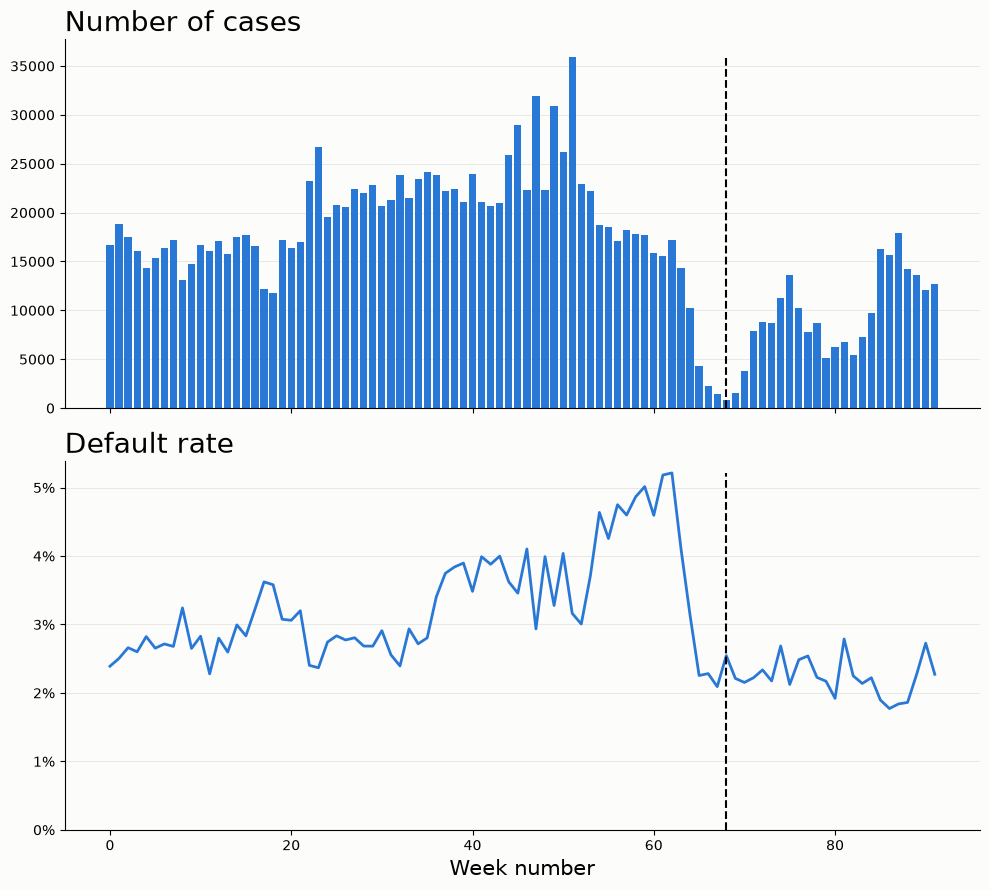

In [5]:
weekly = (pl.scan_parquet(PATH).group_by('WEEK_NUM')
          .agg(cases=pl.len(), defaults=pl.col('target').sum(), rate=pl.col('target').mean()).sort('WEEK_NUM').collect())
print(f'{weekly["defaults"].sum()} defaults in {weekly["cases"].sum()} cases, {weekly["defaults"].mean():.0f} per week on average')

fig, (top, bottom) = plt.subplots(2, 1, figsize=(10, 9), sharex=True, facecolor='#fcfcfb')
top.bar(weekly['WEEK_NUM'], weekly['cases'], width=0.8, color='#2a78d6')
top.set_title('Number of cases', loc='left', fontsize=20)
top.vlines(COVID, 0, weekly['cases'].max(), colors='black', linestyles='dashed')
bottom.plot(weekly['WEEK_NUM'], weekly['rate'], color='#2a78d6', linewidth=2)
bottom.set_ylim(0)
bottom.yaxis.set_major_formatter(lambda v, _: f'{v:.0%}')
bottom.set_xlabel('Week number', fontsize=15)
bottom.set_title('Default rate', loc='left', fontsize=20)
bottom.vlines(COVID, 0, weekly['rate'].max(), colors='black', linestyles='dashed')
for ax in (top, bottom):
    ax.set_facecolor('#fcfcfb')
    ax.grid(axis='y', color='#e6e5e1', linewidth=0.6)
    ax.set_axisbelow(True)
    ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout()
plt.show()

## Scorecard

Grouping, WOE and IV are estimated on the training data only. Numeric attributes are cut into deciles, rare categorical levels
are grouped into `other`, and missing values form their own group.

In [6]:
class FeatureEngineering:
    # Steps 3-5: grouping, WOE transform and IV, all estimated on the training data only

    def __init__(self, bins=10, min_share=0.01):
        self.bins = bins            # quantile groups for numeric attributes
        self.min_share = min_share  # rarer categorical levels are grouped into 'other'

    def group(self, train, c):
        # Missing values form their own group
        if train.schema[c].is_numeric():
            breaks = np.unique(np.quantile(train[c].drop_nulls().to_numpy(), np.arange(1, self.bins) / self.bins))
            return pl.col(c).cut(breaks).cast(pl.String).fill_null('missing')
        g = pl.col(c).cast(pl.String).fill_null('missing')
        shares = train.select(g)[c].value_counts(normalize=True)
        keep = shares.filter(pl.col('proportion') >= self.min_share)[c].to_list()
        return pl.when(g.is_in(keep)).then(g).otherwise(pl.lit('other'))

    def fit(self, train):
        self.groups, self.tables, self.woe, self.iv = {}, {}, {}, {}
        for c in train.columns:
            if c in NON_FEATURES or train[c].n_unique() < 2:
                continue
            g = self.group(train, c)
            # WOE_j = log(D(n_j - D_j) / (D_j(n - D))), IV = sum_j ((n_j - D_j)/(n - D) - D_j/D) WOE_j
            # 0.5 is added to the counts so a group with no defaults (or only defaults) doesn't give an infinite WOE
            t = train.group_by(g.alias('group')).agg(n=pl.len(), D=pl.col('target').sum())
            t = t.with_columns(good=(pl.col('n') - pl.col('D') + 0.5) / (pl.col('n') - pl.col('D') + 0.5).sum(),
                               bad=(pl.col('D') + 0.5) / (pl.col('D') + 0.5).sum())
            t = t.with_columns(woe=(pl.col('good') / pl.col('bad')).log()).sort('group')
            self.groups[c] = g.alias('group')
            self.tables[c] = t
            self.woe[c] = g.replace_strict(t['group'], t['woe'], default=0.0).alias(c)  # unseen groups are neutral
            self.iv[c] = ((t['good'] - t['bad']) * t['woe']).sum()
        self.iv = dict(sorted(self.iv.items(), key=lambda kv: -kv[1]))
        return self

    def transform(self, df, cols=None):
        return df.select(self.woe[c] for c in cols or self.woe)

    def select(self, train, min_iv=0.02, max_corr=0.95):
        # Keep predictive attributes (Siddiqi: IV < 0.02 is unpredictive), strongest first,
        # dropping any that is highly correlated with one already kept
        cols = [c for c, iv in self.iv.items() if iv >= min_iv]
        corr = np.abs(np.corrcoef(self.transform(train, cols).to_numpy(), rowvar=False))
        keep = []
        for i in range(len(cols)):
            if all(corr[i, j] <= max_corr for j in keep):
                keep.append(i)
        return [cols[i] for i in keep]


class Scorecard:
    def __init__(self, min_iv=0.02, max_corr=0.95):
        self.min_iv, self.max_corr = min_iv, max_corr

    def fit(self, train):
        self.fe = FeatureEngineering().fit(train)
        self.features = self.fe.select(train, self.min_iv, self.max_corr)
        X = self.fe.transform(train, self.features).to_numpy()
        self.model = LogisticRegression(C=np.inf, max_iter=1000).fit(X, train['target'].to_numpy())
        return self

    def predict(self, df):
        # Probability of default
        return self.model.predict_proba(self.fe.transform(df, self.features).to_numpy())[:, 1]

## Four models

The depth 0 set is the columns of the base and static tables; the bureau set adds the aggregated bureau columns. Attributes are
selected separately for each set. Missing values are their own level for CatBoost's categorical attributes.

In [7]:
data = pl.scan_parquet(PATH).gather_every(EVERY)
names = data.collect_schema().names()
depth0 = {c for f in DEPTH0 for c in pl.scan_csv(DIR + f).collect_schema().names()}
sets = {'depth 0': [c for c in names if c in depth0], 'depth 0 + bureau': names}
train = data.filter(pl.col('WEEK_NUM') <= TRAIN_END).collect()
test = data.filter(pl.col('WEEK_NUM').is_between(TRAIN_END + 1, TEST_END)).collect()
print(f'train: {train.height} cases, weeks {train["WEEK_NUM"].min()}-{train["WEEK_NUM"].max()}, default rate {train["target"].mean():.4f}')
print(f'test:  {test.height} cases, weeks {test["WEEK_NUM"].min()}-{test["WEEK_NUM"].max()}, default rate {test["target"].mean():.4f}')

train: 1395111 cases, weeks 0-80, default rate 0.0324
test:  131548 cases, weeks 81-91, default rate 0.0212


In [8]:
# scores: one row per case with the PD of each model
period = (pl.when(pl.col('WEEK_NUM') > TRAIN_END).then(pl.lit('test'))
          .when(pl.col('WEEK_NUM') < COVID).then(pl.lit('train, before covid')).otherwise(pl.lit('train, after covid')))
scores = pl.concat([df.select('WEEK_NUM', 'target', period=period) for df in (train, test)])
for name, cols in sets.items():
    sc = Scorecard(MIN_IV, MAX_CORR).fit(train.select(cols))
    cats = [c for c in sc.features if not train.schema[c].is_numeric()]
    raw = [df.select(sc.features).with_columns(pl.col(cats).cast(pl.String).fill_null('missing')).to_pandas() for df in (train, test)]
    model = CatBoostClassifier(iterations=300, learning_rate=0.05, depth=6, random_seed=0, verbose=0, allow_writing_files=False,
                               cat_features=cats).fit(raw[0], train['target'].to_numpy())
    print(f'{name}: {len(sc.fe.iv)} attributes, {len(sc.features)} selected (IV >= {MIN_IV}, correlation <= {MAX_CORR}). Highest IV:')
    for c in list(sc.fe.iv)[:TOP]:
        print(f'  {c:45s} IV {sc.fe.iv[c]:.3f}{"" if c in sc.features else "  (left out, correlated)"}')
    scores = scores.with_columns(
        pl.Series(f'logistic, {name}', np.concatenate([sc.predict(df) for df in (train, test)])),
        pl.Series(f'catboost, {name}', np.concatenate([model.predict_proba(X)[:, 1] for X in raw])))
MODELS = scores.columns[3:]

depth 0: 214 attributes, 96 selected (IV >= 0.02, correlation <= 0.95). Highest IV:
  avgdpdtolclosure24_3658938P                   IV 0.310
  pctinstlsallpaidlate1d_3546856L               IV 0.278
  maxdbddpdtollast12m_3658940P                  IV 0.250
  pctinstlsallpaidlate4d_3546849L               IV 0.246
  avgdbddpdlast24m_3658932P                     IV 0.238
  pctinstlsallpaidlate6d_3546844L               IV 0.227
  daysoverduetolerancedd_3976961L               IV 0.221
  pctinstlsallpaidearl3d_427L                   IV 0.216
  maxdpdlast24m_143P                            IV 0.214
  numinstlswithdpd10_728L                       IV 0.214
  pctinstlsallpaidlat10d_839L                   IV 0.205
  lastrejectreason_759M                         IV 0.199
  maxdpdlast12m_727P                            IV 0.194
  maxdpdtolerance_374P                          IV 0.194
  lastrejectdate_50D                            IV 0.191
  maxdbddpdtollast6m_4187119P                   IV 0.186
  ma

depth 0 + bureau: 710 attributes, 204 selected (IV >= 0.02, correlation <= 0.95). Highest IV:
  avgdpdtolclosure24_3658938P                   IV 0.310
  mean_dpdmax_757P                              IV 0.291
  pctinstlsallpaidlate1d_3546856L               IV 0.278
  mean_dpdmax_139P                              IV 0.266
  mean_overdueamountmax_35A                     IV 0.259
  max_dpdmax_139P                               IV 0.255  (left out, correlated)
  mean_overdueamountmax2_398A                   IV 0.253  (left out, correlated)
  maxdbddpdtollast12m_3658940P                  IV 0.250
  pctinstlsallpaidlate4d_3546849L               IV 0.246
  max_dpdmax_757P                               IV 0.241
  avgdbddpdlast24m_3658932P                     IV 0.238
  mean_numberofoverdueinstlmax_1039L            IV 0.237
  sum_dpdmax_139P                               IV 0.237
  mean_overdueamountmax_155A                    IV 0.237
  max_numberofoverdueinstlmax_1039L             IV 0.232  (l

## AUC

Uplift is the AUC with the bureau data minus the AUC without. Only the test rows are out of sample.

In [9]:
def aucs(scores, by):
    rows = [{by: k[0], 'cases': g.height, **{m: roc_auc_score(g['target'], g[m]) for m in MODELS}}
            for k, g in scores.group_by(by, maintain_order=True)]
    return pl.DataFrame(rows).with_columns((pl.col(f'{m}, depth 0 + bureau') - pl.col(f'{m}, depth 0')).alias(f'{m}, uplift')
                                           for m in ('logistic', 'catboost'))


weekly_auc = aucs(scores.sort('WEEK_NUM'), 'WEEK_NUM')
with pl.Config(tbl_cols=10, float_precision=4):
    display(aucs(scores, 'period'))
for name, w in (('all weeks', weekly_auc), ('test weeks', weekly_auc.filter(pl.col('WEEK_NUM') > TRAIN_END))):
    print(f'average weekly AUC uplift from bureau data, {name}: logistic {w["logistic, uplift"].mean():+.4f}, catboost {w["catboost, uplift"].mean():+.4f}')

period,cases,"logistic, depth 0","catboost, depth 0","logistic, depth 0 + bureau","catboost, depth 0 + bureau","logistic, uplift","catboost, uplift"
str,i64,f64,f64,f64,f64,f64,f64
"""train, before covid""",1300320,0.7725,0.7954,0.8094,0.8268,0.0370,0.0314
"""train, after covid""",94791,0.8016,0.8188,0.8348,0.8489,0.0333,0.0300
"""test""",131548,0.8109,0.8295,0.8424,0.8559,0.0315,0.0265


average weekly AUC uplift from bureau data, all weeks: logistic +0.0342, catboost +0.0301
average weekly AUC uplift from bureau data, test weeks: logistic +0.0305, catboost +0.0257


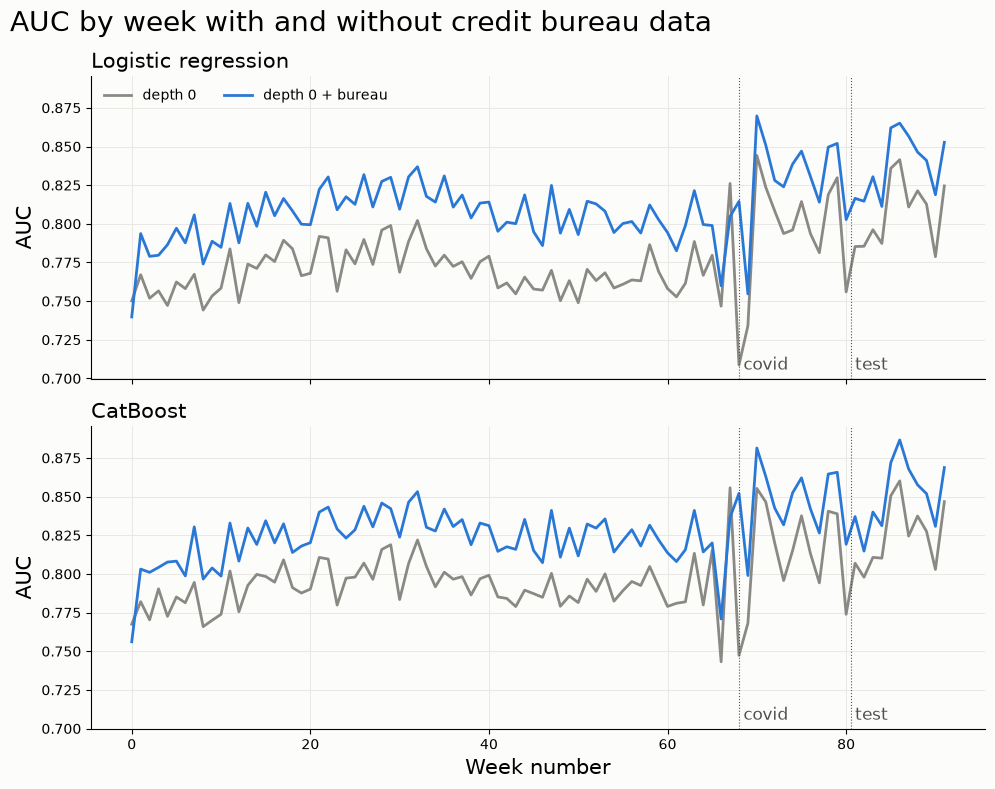

In [10]:
fig, axes = plt.subplots(2, 1, figsize=(10, 8), sharex=True, sharey=True, facecolor='#fcfcfb')
for ax, m in zip(axes, ('logistic', 'catboost')):
    ax.set_facecolor('#fcfcfb')
    for name, color in zip(sets, ('#8a8984', '#2a78d6')):
        ax.plot(weekly_auc['WEEK_NUM'], weekly_auc[f'{m}, {name}'], color=color, linewidth=2, label=name)
    for week, label in ((COVID, 'covid'), (TRAIN_END + 0.5, 'test')):
        ax.axvline(week, color='#52514e', linewidth=0.8, linestyle=':')
        ax.text(week + 0.5, 0.03, label, fontsize=12, color='#52514e', transform=ax.get_xaxis_transform())
    ax.set_ylabel('AUC', fontsize=15)
    ax.set_title({'logistic': 'Logistic regression', 'catboost': 'CatBoost'}[m], loc='left', fontsize=15)
    ax.grid(color='#e6e5e1', linewidth=0.6)
    ax.set_axisbelow(True)
    ax.spines[['top', 'right']].set_visible(False)
axes[0].legend(frameon=False, loc='upper left', ncols=2)
axes[1].set_xlabel('Week number', fontsize=15)
fig.suptitle('AUC by week with and without credit bureau data', x=0.01, ha='left', fontsize=20)
fig.tight_layout()
plt.show()

## Calibration

Actual default rate against the mean predicted PD of each model.

In [11]:
def calibration(scores):
    return scores.group_by('period', maintain_order=True).agg(pl.len().alias('cases'), pl.col('target').mean().alias('actual'),
                                                              pl.col(MODELS).mean())


with pl.Config(tbl_cols=10, float_precision=4):
    display(calibration(scores))

period,cases,actual,"logistic, depth 0","catboost, depth 0","logistic, depth 0 + bureau","catboost, depth 0 + bureau"
str,u32,f64,f64,f64,f64,f64
"""train, before covid""",1300320,0.0331,0.0327,0.0326,0.0327,0.0326
"""train, after covid""",94791,0.0230,0.0296,0.0283,0.0276,0.0275
"""test""",131548,0.0212,0.0295,0.0288,0.0283,0.0288


The PDs are then recalibrated to the default rate known at the end of the training weeks: the intercept of each model is shifted
(the same change in log-odds for every case) so that its mean PD over the last `RECAL` training weeks equals the default rate
observed there. The shifted PDs are used from the first of those weeks on. AUCs within a week are unchanged.

In [12]:
start = TRAIN_END - RECAL + 1
recent = scores.filter(pl.col('WEEK_NUM').is_between(start, TRAIN_END))
print(f'default rate in weeks {start}-{TRAIN_END}: {recent["target"].mean():.4f}')
for m in MODELS:
    shift = brentq(lambda d: expit(logit(recent[m].to_numpy()) + d).mean() - recent['target'].mean(), -5, 5)
    print(f'{m}: intercept shifted by {shift:+.3f} from week {start} on')
    scores = scores.with_columns(pl.when(pl.col('WEEK_NUM') >= start).then(1 / (1 + (1 / pl.col(m) - 1) * np.exp(-shift))).otherwise(pl.col(m)).alias(m))

with pl.Config(tbl_cols=10, float_precision=4):
    display(calibration(scores))

default rate in weeks 68-80: 0.0230
logistic, depth 0: intercept shifted by -0.271 from week 68 on


catboost, depth 0: intercept shifted by -0.223 from week 68 on
logistic, depth 0 + bureau: intercept shifted by -0.199 from week 68 on
catboost, depth 0 + bureau: intercept shifted by -0.195 from week 68 on


period,cases,actual,"logistic, depth 0","catboost, depth 0","logistic, depth 0 + bureau","catboost, depth 0 + bureau"
str,u32,f64,f64,f64,f64,f64
"""train, before covid""",1300320,0.0331,0.0327,0.0326,0.0327,0.0326
"""train, after covid""",94791,0.0230,0.0230,0.0230,0.0230,0.0230
"""test""",131548,0.0212,0.0229,0.0234,0.0236,0.0241


## Loss avoided and net benefit

Expected loss is EL = PD x LGD x EAD. Every case in the data was approved by the lender, so a model can only turn approved cases
into rejections. It avoids the loss LGD x EAD on the rejected cases that defaulted, and turns away the lending to the rejected
cases that did not default, which costs MARGIN x EAD. Applicants the lender rejected are not in the data, so good applicants a
model would have let in are not counted.

On the test weeks, every model rejects the same share `REJECT` of the cases, the ones it gives the highest PD. The models are then
compared at the same operating point, and the result depends only on how each model ranks the cases, not on its calibration.
With these assumptions rejecting a case pays when PD x LGD > (1 - PD) x MARGIN, a PD above MARGIN / (MARGIN + LGD); the PD
cut-off column shows the recalibrated PD each model's rejections start at.

In [13]:
t = scores.with_columns(ead=pl.concat([df[EAD] for df in (train, test)])).filter(pl.col('period') == 'test')
y, ead = t['target'].to_numpy(), t['ead'].to_numpy()
pds = {m: t[m].to_numpy() for m in MODELS}
loss = LGD * (ead * y).sum()


def rejected(p, share):
    # The share of the cases with the highest PD
    return np.argsort(-p)[:int(share * len(p))]


rows = []
for m in MODELS:
    r = rejected(pds[m], REJECT)
    rows.append({'model': m, 'rejected': len(r), 'PD cut-off': pds[m][r].min(), 'defaults among rejected': y[r].sum(),
                 'loss avoided': LGD * (ead[r] * y[r]).sum(), 'share of loss': LGD * (ead[r] * y[r]).sum() / loss,
                 'good lending turned away': (ead[r] * (1 - y[r])).sum()})
    rows[-1]['net benefit'] = rows[-1]['loss avoided'] - MARGIN * rows[-1]['good lending turned away']
print(f'Test weeks: {len(y)} cases, {y.sum()} defaults, lending {ead.sum():,.0f}, loss {loss:,.0f} (LGD {LGD}). '
      f'Rejecting the {REJECT:.0%} with the highest PD; rejecting pays above a PD of {MARGIN / (MARGIN + LGD):.3f}:')
with pl.Config(tbl_cols=10, float_precision=3, thousands_separator=',', fmt_str_lengths=30):
    display(pl.DataFrame(rows))
net = {r['model']: r['net benefit'] for r in rows}
for m in ('logistic', 'catboost'):
    value = net[f'{m}, depth 0 + bureau'] - net[f'{m}, depth 0']
    print(f'{m}: net benefit of the bureau data {value:,.0f}, {value / ead.sum():.4%} of the lending in the test weeks, {value / len(y):.1f} per application')

Test weeks: 131548 cases, 2788 defaults, lending 7,378,852,448, loss 93,668,218 (LGD 0.5). Rejecting the 3% with the highest PD; rejecting pays above a PD of 0.138:


model,rejected,PD cut-off,defaults among rejected,loss avoided,share of loss,good lending turned away,net benefit
str,i64,f64,i64,f64,f64,f64,f64
"""logistic, depth 0""","3,946",0.095,586,"21,948,577.407",0.234,"229,081,173.168","3,622,083.553"
"""catboost, depth 0""","3,946",0.097,711,"28,743,229.116",0.307,"226,838,372.379","10,596,159.326"
"""logistic, depth 0 + bureau""","3,946",0.114,671,"25,642,755.106",0.274,"218,781,629.742","8,140,224.727"
"""catboost, depth 0 + bureau""","3,946",0.111,814,"33,015,872.815",0.352,"217,271,119.877","15,634,183.224"


logistic: net benefit of the bureau data 4,518,141, 0.0612% of the lending in the test weeks, 34.3 per application
catboost: net benefit of the bureau data 5,038,024, 0.0683% of the lending in the test weeks, 38.3 per application


Net benefit against the share of cases rejected, as a share of the lending in the test weeks. The dotted line is `REJECT`.

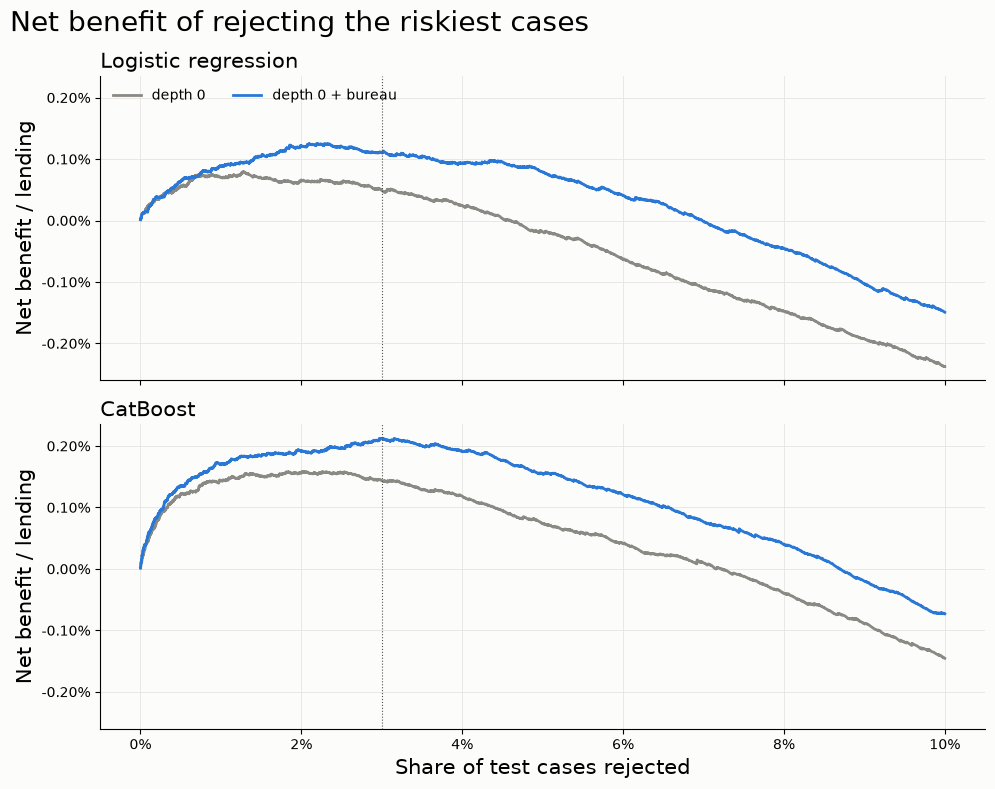

In [14]:
fig, axes = plt.subplots(2, 1, figsize=(10, 8), sharex=True, sharey=True, facecolor='#fcfcfb')
for ax, m in zip(axes, ('logistic', 'catboost')):
    ax.set_facecolor('#fcfcfb')
    for name, color in zip(sets, ('#8a8984', '#2a78d6')):
        r = rejected(pds[f'{m}, {name}'], 0.1)
        curve = np.cumsum(LGD * ead[r] * y[r] - MARGIN * ead[r] * (1 - y[r])) / ead.sum()
        ax.plot(np.arange(1, len(r) + 1) / len(y), curve, color=color, linewidth=2, label=name)
    ax.axvline(REJECT, color='#52514e', linewidth=0.8, linestyle=':')
    ax.xaxis.set_major_formatter(lambda v, _: f'{v:.0%}')
    ax.yaxis.set_major_formatter(lambda v, _: f'{v:.2%}')
    ax.set_ylabel('Net benefit / lending', fontsize=15)
    ax.set_title({'logistic': 'Logistic regression', 'catboost': 'CatBoost'}[m], loc='left', fontsize=15)
    ax.grid(color='#e6e5e1', linewidth=0.6)
    ax.set_axisbelow(True)
    ax.spines[['top', 'right']].set_visible(False)
axes[0].legend(frameon=False, loc='upper left', ncols=2)
axes[1].set_xlabel('Share of test cases rejected', fontsize=15)
fig.suptitle('Net benefit of rejecting the riskiest cases', x=0.01, ha='left', fontsize=20)
fig.tight_layout()
plt.show()

## Uncertainty

The test cases are resampled with replacement `BOOT` times. For each resample the AUCs and the net benefits at the rejection
share `REJECT` are recalculated, and the 2.5% and 97.5% percentiles of each difference give a 95% interval. The models are
not refitted, so the intervals cover the sampling of the test cases only. Net benefit is a share of lending.

In [15]:
def measures(i):
    # AUC and net benefit / lending of each model on the test cases i
    out = {}
    for m in MODELS:
        r = i[rejected(pds[m][i], REJECT)]
        out['AUC', m] = roc_auc_score(y[i], pds[m][i])
        out['net benefit', m] = (LGD * ead[r] * y[r] - MARGIN * ead[r] * (1 - y[r])).sum() / ead[i].sum()
    return out


DIFFS = [('bureau data, logistic', 'logistic, depth 0 + bureau', 'logistic, depth 0'),
         ('bureau data, catboost', 'catboost, depth 0 + bureau', 'catboost, depth 0'),
         ('catboost - logistic, depth 0', 'catboost, depth 0', 'logistic, depth 0'),
         ('catboost - logistic, depth 0 + bureau', 'catboost, depth 0 + bureau', 'logistic, depth 0 + bureau'),
         ('catboost depth 0 - logistic with bureau', 'catboost, depth 0', 'logistic, depth 0 + bureau')]
rng = np.random.default_rng(0)
full = measures(np.arange(len(y)))
boot = [measures(rng.integers(0, len(y), len(y))) for _ in range(BOOT)]
rows = []
for k in ('AUC', 'net benefit'):
    for name, a, b in DIFFS:
        d = np.array([s[k, a] - s[k, b] for s in boot])
        rows.append({'measure': k, 'difference': name, 'estimate': full[k, a] - full[k, b],
                     'low': np.quantile(d, 0.025), 'high': np.quantile(d, 0.975), 'share above 0': (d > 0).mean()})
with pl.Config(tbl_rows=20, float_precision=5, fmt_str_lengths=45):
    display(pl.DataFrame(rows))

measure,difference,estimate,low,high,share above 0
str,str,f64,f64,f64,f64
"""AUC""","""bureau data, logistic""",0.03149,0.02678,0.03578,1.00000
"""AUC""","""bureau data, catboost""",0.02647,0.02285,0.03066,1.00000
"""AUC""","""catboost - logistic, depth 0""",0.01851,0.01542,0.02140,1.00000
"""AUC""","""catboost - logistic, depth 0 + bureau""",0.01350,0.01069,0.01635,1.00000
"""AUC""","""catboost depth 0 - logistic with bureau""",-0.01297,-0.01782,-0.00837,0.00000
"""net benefit""","""bureau data, logistic""",0.00061,0.00034,0.00086,1.00000
"""net benefit""","""bureau data, catboost""",0.00068,0.00044,0.00092,1.00000
"""net benefit""","""catboost - logistic, depth 0""",0.00095,0.00067,0.00121,1.00000
"""net benefit""","""catboost - logistic, depth 0 + bureau""",0.00102,0.00074,0.00126,1.00000
